In [1]:
# ---
# jupyter:
#   jupytext:
#     text_representation:
#       extension: .py
#       format_name: percent
#   kernelspec:
#     display_name: Python 3
#     language: python
#     name: python3
# ---

# 06 · Results summary

Notebooks 03-05 estimate the toll's first-year effect on taxi and
ride-hail trips starting in the CBD three ways. This notebook puts them
side by side, draws the summary figure and writes the numbers the README
and decision memo quote.

In [2]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from congestion.plots import COLORS, read_metrics, save, style, write_metrics

style()
audit, trends, did, fc, sc = (read_metrics(n) for n in ["data_audit", "trends", "did", "forecast", "synth"])

In [3]:
rows = [
    {"method": "DiD: 2025 vs 2024", "accounts_for_trend": False,
     "effect": did["quick_2025_vs_2024"]["effect"], "low": did["quick_2025_vs_2024"]["ci_low"],
     "high": did["quick_2025_vs_2024"]["ci_high"], "note": "95% CI"},
    {"method": "DiD: 2024 vs 2023 (no toll)", "accounts_for_trend": False,
     "effect": did["placebo_2024_vs_2023"]["effect"], "low": did["placebo_2024_vs_2023"]["ci_low"],
     "high": did["placebo_2024_vs_2023"]["ci_high"], "note": "95% CI; placebo"},
    {"method": "Synthetic control (standard)", "accounts_for_trend": False,
     "effect": sc["standard_effect_2025"], "low": np.nan, "high": np.nan,
     "note": f"placebo p = {sc['standard_p_value']:.2f}"},
    {"method": "DiD with zone trends", "accounts_for_trend": True,
     "effect": did["main_trend_adjusted_year1"]["effect"], "low": did["main_trend_adjusted_year1"]["ci_low"],
     "high": did["main_trend_adjusted_year1"]["ci_high"],
     "note": f"95% CI; fake dates: typical ±{did['fake_dates']['trend_adjusted_rms']:.1%}"},
    {"method": "DiD, two-step (pre-toll zone trends)", "accounts_for_trend": True,
     "effect": did["two_step_pre_trend_year1"]["effect"], "low": did["two_step_pre_trend_year1"]["ci_low"],
     "high": did["two_step_pre_trend_year1"]["ci_high"],
     "note": f"95% CI; fake dates: typical ±{did['fake_dates']['two_step_rms']:.1%}"},
    {"method": "Forecast: CBD vs its own forecast", "accounts_for_trend": True,
     "effect": fc["gap_2025"]["cbd"], "low": fc["gap_2025"]["cbd"] - fc["placebo_noise_max_abs"],
     "high": fc["gap_2025"]["cbd"] + fc["placebo_noise_max_abs"],
     "note": f"± largest no-toll backtest gap; {fc['gap_2025_net_of_backtest']['cbd']:+.1%} net of backtest bias"},
    {"method": "Forecast: CBD gap minus Manhattan gap", "accounts_for_trend": True,
     "effect": fc["gap_2025"]["cbd_minus_manhattan"], "low": np.nan, "high": np.nan,
     "note": f"{fc['gap_2025_net_of_backtest']['cbd_minus_manhattan']:+.1%} net of backtest bias"},
    {"method": "Synthetic control (trend-adjusted)", "accounts_for_trend": True,
     "effect": sc["trend_adjusted_effect_2025"], "low": np.nan, "high": np.nan,
     "note": f"placebo p = {sc['trend_adjusted_p_value']:.2f}"},
]
table = pd.DataFrame(rows)
table.to_csv("reports/metrics/methods_comparison.csv", index=False)
table.style.format({"effect": "{:+.1%}", "low": "{:+.1%}", "high": "{:+.1%}"}, na_rep="")

,method,accounts_for_trend,effect,low,high,note
0,DiD: 2025 vs 2024,False,-2.6%,-4.0%,-1.2%,95% CI
1,DiD: 2024 vs 2023 (no toll),False,-4.4%,-5.3%,-3.5%,95% CI; placebo
2,Synthetic control (standard),False,-6.7%,,,placebo p = 0.18
3,DiD with zone trends,True,+1.0%,-0.3%,+2.3%,95% CI; fake dates: typical ±4.3%
4,"DiD, two-step (pre-toll zone trends)",True,+1.2%,-0.1%,+2.5%,95% CI; fake dates: typical ±4.2%
5,Forecast: CBD vs its own forecast,True,-0.7%,-2.1%,+0.7%,± largest no-toll backtest gap; +0.3% net of backtest bias
6,Forecast: CBD gap minus Manhattan gap,True,+2.3%,,,+1.3% net of backtest bias
7,Synthetic control (trend-adjusted),True,+0.3%,,,placebo p = 0.93


Every method that ignores the CBD's pre-existing decline finds a 3-7% drop,
and so does the no-toll placebo year. Every method that accounts for it
finds an effect within about ±2% of zero. None of them can rule out a
small effect: on fake toll dates the trend-adjusted DiD finds "effects" of
about ±4% (notebook 03, section 4b), and the forecast's no-toll backtests
miss by up to ±1.4%.

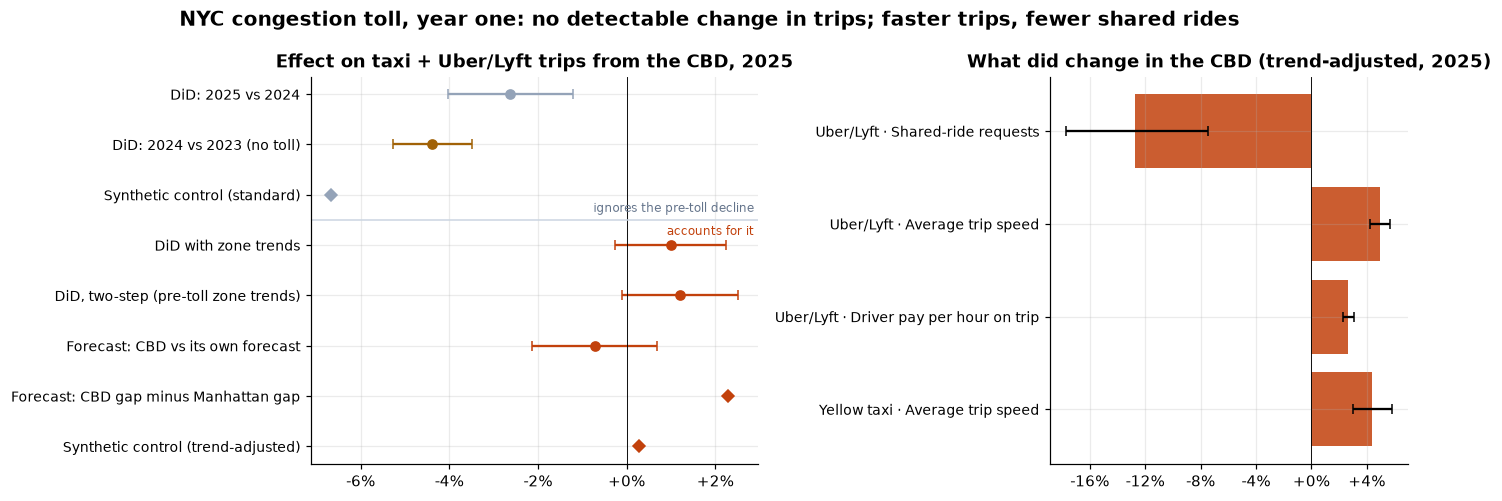

In [4]:
other = pd.read_csv("reports/metrics/did_other_outcomes.csv")
clear = other[other["clear"]].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
order = table.iloc[::-1].reset_index(drop=True)
for i, r in order.iterrows():
    c = COLORS["cbd"] if r["accounts_for_trend"] else "#94A3B8"
    if r["method"].startswith("DiD: 2024 vs 2023"):
        c = "#A16207"
    if np.isfinite(r["low"]):
        ax.errorbar(r["effect"], i, xerr=[[r["effect"] - r["low"]], [r["high"] - r["effect"]]],
                    fmt="o", color=c, capsize=3)
    else:
        ax.plot(r["effect"], i, "D", color=c)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order["method"], fontsize=9)
ax.axvline(0, color="black", lw=0.6)
ax.axhline(4.5, color="#CBD5E1", lw=1)
ax.text(0.99, 4.6, "ignores the pre-toll decline", transform=ax.get_yaxis_transform(), ha="right",
        va="bottom", fontsize=8, color="#64748B")
ax.text(0.99, 4.4, "accounts for it", transform=ax.get_yaxis_transform(), ha="right", va="top",
        fontsize=8, color=COLORS["cbd"])
ax.xaxis.set_major_locator(plt.MultipleLocator(0.02))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_title("Effect on taxi + Uber/Lyft trips from the CBD, 2025")

ax = axes[1]
lab = clear["service"] + " · " + clear["outcome"]
y = np.arange(len(clear))[::-1]
ax.barh(y, clear["effect"], color=COLORS["cbd"], alpha=0.85)
ax.errorbar(clear["effect"], y, xerr=[clear["effect"] - clear["ci_low"], clear["ci_high"] - clear["effect"]],
            fmt="none", ecolor="black", capsize=3)
ax.set_yticks(y)
ax.set_yticklabels(lab, fontsize=9)
ax.axvline(0, color="black", lw=0.6)
ax.xaxis.set_major_locator(plt.MultipleLocator(0.04))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_title("What did change in the CBD (trend-adjusted, 2025)")
fig.suptitle("NYC congestion toll, year one: no detectable change in trips; faster trips, fewer shared rides", fontweight="bold",
             fontsize=13)
fig.tight_layout()
save(fig, "06_hero_summary.png")
plt.show()

## How sensitive is demand to the fee?

The fee raised the price of a CBD trip by about 4% (notebook 03, section 7).
Dividing a change in trips by that change in price gives a price
elasticity. The trip estimates are all near zero, so the useful number is
the most negative elasticity each method still allows: its lowest
plausible trip change divided by the price change.

In [5]:
price = did["fee_share_of_fare_2025"]
fc_low = fc["gap_2025"]["cbd"] - fc["placebo_noise_max_abs"]
did_low = did["main_trend_adjusted_year1"]["effect"] - 2 * did["fake_dates"]["trend_adjusted_rms"]
elasticity = {
    "price_increase": price,
    "forecast_lowest_trip_change": fc_low,
    "forecast_elasticity_bound": float(np.log1p(fc_low) / np.log1p(price)),
    "did_lowest_trip_change": did_low,
    "did_elasticity_bound": float(np.log1p(did_low) / np.log1p(price)),
}
print(f"Price of a CBD trip: +{price:.1%} (fee / fare)")
print(f"Forecast check: trips no lower than {fc_low:+.1%} -> elasticity no more negative than "
      f"{elasticity['forecast_elasticity_bound']:.1f}")
print(f"DiD (effect - 2 x fake-date noise): {did_low:+.1%} -> {elasticity['did_elasticity_bound']:.1f}")

Price of a CBD trip: +4.3% (fee / fare)
Forecast check: trips no lower than -2.1% -> elasticity no more negative than -0.5
DiD (effect - 2 x fake-date noise): -7.6% -> -1.9


The forecast check, the tightest of the three, rules out an elasticity
much beyond −0.5: a 4% price rise cost at most about 2% of trips. The DiD
on its own is too noisy to rule out much (its bound is near −2). Demand for
trips in the CBD looks inelastic to a fee of this size, at least in the
first year.

In [6]:
lo_hi = [float(table.loc[table["accounts_for_trend"], "effect"].min()),
         float(table.loc[table["accounts_for_trend"], "effect"].max())]
naive = [float(table.loc[~table["accounts_for_trend"] & ~table["method"].str.contains("no toll"), "effect"].min()),
         float(table.loc[~table["accounts_for_trend"] & ~table["method"].str.contains("no toll"), "effect"].max())]
write_metrics("summary", {
    "trips_kept": audit["trips_kept"],
    "trend_adjusted_range": lo_hi,
    "naive_range": naive,
    "main_effect": did["main_trend_adjusted_year1"]["effect"],
    "main_ci": [did["main_trend_adjusted_year1"]["ci_low"], did["main_trend_adjusted_year1"]["ci_high"]],
    "fake_date_rms_trend_adjusted": did["fake_dates"]["trend_adjusted_rms"],
    "fake_date_range_trend_adjusted": did["fake_dates"]["trend_adjusted_range"],
    "fake_date_range_quick": did["fake_dates"]["quick_range"],
    "speed_uber": float(other.loc[(other["service"] == "Uber/Lyft") & (other["outcome"] == "Average trip speed"), "effect"].iloc[0]),
    "speed_taxi": float(other.loc[(other["service"] == "Yellow taxi") & (other["outcome"] == "Average trip speed"), "effect"].iloc[0]),
    "wait_uber": float(other.loc[(other["service"] == "Uber/Lyft") & (other["outcome"].str.startswith("Wait")), "effect"].iloc[0]),
    "pay_per_hour_uber": float(other.loc[(other["service"] == "Uber/Lyft") & (other["outcome"].str.startswith("Driver pay")), "effect"].iloc[0]),
    "year2_did": did["trend_adjusted_year2_2026"]["effect"],
    "year2_forecast_cbd_minus_manhattan": fc["gap_2026"]["cbd_minus_manhattan"],
    "shared_requests_uber": float(other.loc[(other["service"] == "Uber/Lyft")
                                            & (other["outcome"] == "Shared-ride requests"), "effect"].iloc[0]),
    "two_step_effect": did["two_step_pre_trend_year1"]["effect"],
    "forecast_net_of_backtest": fc["gap_2025_net_of_backtest"],
    "elasticity": elasticity,
})
lo_hi, naive

Saved reports/metrics/summary.json


([-0.007232637708038542, 0.02290884193917564],
 [-0.0666151371498164, -0.026266427436976564])